# 검수 파이프라인 end-to-end — SAM3 탐지 + bbox 미표시 배치 VLM 설명

### 이 노트북이 다루는 것
크롭 방식과의 비교는 끝났다(`vlm_description_check.ipynb` §4/§4-1 참고, 결론: 배치 방식이 문체·구체성 면에서 원하는 느낌에 더 가까웠다). 이 노트북은 그 비교를 다시 하지 않고, **실제로 쓸 파이프라인 하나만** 끝까지 다룬다:

```
원본 이미지
  -> (1) SAM3로 하자 탐지 (garment 1회 세그먼트 -> 하자 탐지, bbox/유형)
  -> (2) 원본 이미지(bbox 미표시) + 번호별 위치·유형 텍스트로 VLM 배치 설명 1회 호출
  -> (3) 번호별로 파싱 + bbox/유형과 매칭 -> 최종 JSON
```

**출력 JSON에 들어가는 것**: `bbox`(좌표) · `defect_type`/`label`(유형) · `description`(VLM 설명). **`상태`(사용자 응답)는 여기서 만들지 않는다** — AI는 판정만 하고, 사용자가 이 finding을 인정/거부했는지는 BE가 `key`로 관리한다(빨강/초록 박스 전환은 FE가 좌표 기반으로 직접 그리는 것이라 서버가 그린 정적 이미지로는 할 수 없다 — 그래서 좌표를 JSON으로 준다).

### 실행 순서
0. 의존성 설치 -> HF 로그인 -> GPU 확인 -> 설정 -> SAM3/VLM 모델 로드 -> 테스트 이미지
1. Step 1 — SAM3 실시간 탐지(garment 1회 세그먼트 -> 하자 탐지 -> 공통 후처리)
2. Step 2 — bbox 미표시 배치 VLM 설명 1회 호출 + 파싱
3. Step 3 — 최종 JSON 조립(bbox+유형+설명)
4. 이미지 전체 배치 실행 + 결과 저장

**프로덕션(`app/`, `worker/`)은 건드리지 않는다.** 여기서 검증되면 별도 계획 문서로 반영 여부를 결정한다.


## 0. 의존성 설치


In [ ]:
# %pip install -q -r "../sam3-condition-check/requirements-sam3.txt"
# %pip install -q -r "requirements-vlm.txt"


## 0-1. Hugging Face 로그인 (SAM3 gated repo)


In [2]:
import os

from huggingface_hub import login

hf_token = os.getenv("HF_TOKEN")
if hf_token:
    login(token=hf_token)
    print("HF_TOKEN 환경변수로 로그인했습니다.")
else:
    print("HF_TOKEN이 없습니다 — huggingface-cli login을 미리 실행했다면 그대로 진행됩니다.")


c:\Users\SSAFY\miniforge3\envs\qual\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF_TOKEN 환경변수로 로그인했습니다.


## 0-2. CUDA / GPU 확인


In [1]:
import torch

print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))


cuda available: True
device: NVIDIA GeForce RTX 4070 Laptop GPU


## 0-3. 경로·설정


In [3]:
import sys

# 공유 유틸(qc_shared.py)은 이 폴더의 부모(validation/QUAL/)에 있다.
sys.path.insert(0, "..")
# SAM3 호출/크롭 유틸과 검증된 bbox 파이프라인(garment 탐지 -> 하자 탐지 -> 후처리)은
# 새로 만들지 않고 형제 스파이크 폴더의 구현을 그대로 재사용한다.
sys.path.insert(0, "../sam3-parts-segment-check")
sys.path.insert(0, "../sam3-border-overlay-check")
# 저장소 루트 — 위치 힌트를 카테고리별 실제 부위명으로 바꿀 때 프로덕션의 부위
# taxonomy(worker.models.sam3.contracts/prompts)를 그대로 재사용하려고 추가한다.
sys.path.insert(0, "../../../../")

import json as jsonlib
import time

import matplotlib.pyplot as plt
from PIL import Image

import qc_shared
from border_overlay_check import run_one
from sam3_caller import Sam3Caller

import model_registry
from loaders import (
    build_batch_prompt,
    describe_defects_batch,
    draw_numbered_boxes,
    garment_section_label_ko,
    generate_from_image,
    load_qwen_vl,
    missing_batch_numbers,
    parse_batch_response,
)

qc_shared.use_korean_font()  # 그래프 제목 한글이 두부(□□)로 깨지지 않게


'Malgun Gothic'

## 0-4. SAM3 모델 로드 (하자 탐지용)


In [4]:
sam3_caller = Sam3Caller()
sam3_caller._ensure_loaded()


[Sam3Caller] 로딩 중... (model=facebook/sam3, device=cuda)


Loading weights: 100%|██████████| 1468/1468 [00:00<00:00, 2483.94it/s]


[Sam3Caller] 로드 완료


## 0-5. VLM 모델 로드 (설명 생성용)


In [5]:
print(f"모델: {model_registry.ACTIVE_VLM} ({model_registry.VLM_MODELS[model_registry.ACTIVE_VLM]})")
vlm_bundle = load_qwen_vl(
    model_registry.VLM_MODELS[model_registry.ACTIVE_VLM],
    quantization=model_registry.ACTIVE_QUANTIZATION,
)
print("VLM 로드 완료")

# 워밍업 — 더미 입력으로 한 번 태워서 CUDA 커널/캐시 초기화 비용을 여기서 미리 낸다.
# 이후 셀에서 재는 시간은 이 비용이 빠진 "캐시된 상태"의 순수 추론시간이다.
_warmup_started = time.perf_counter()
_warmup_image = Image.new("RGB", (224, 224), color=(128, 128, 128))
generate_from_image(vlm_bundle, _warmup_image, "이 이미지를 한 단어로 설명해.", max_new_tokens=4)
print(f"VLM 워밍업 완료 ({time.perf_counter() - _warmup_started:.1f}초, 이 비용은 이후 측정에 안 들어감)")


모델: qwen3-vl-4b-instruct (Qwen/Qwen3-VL-4B-Instruct)


W0806 15:38:41.527000 16572 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Loading weights: 100%|██████████| 713/713 [00:05<00:00, 136.49it/s]


VLM 로드 완료


## 0-6. 테스트 이미지 로드


이미지 12장: ['black_stain.png', 'black_washed.jpg', 'denim.jpg', 'fix.jpg', 'levis_patch.jpg', 'logo_test.jpg', 'navy_logo.png', 'navy_trucker.jpg', 'scratch.jpg', 'shirt_red.png', 'small_pro.jpg', 'vintage_t.png']


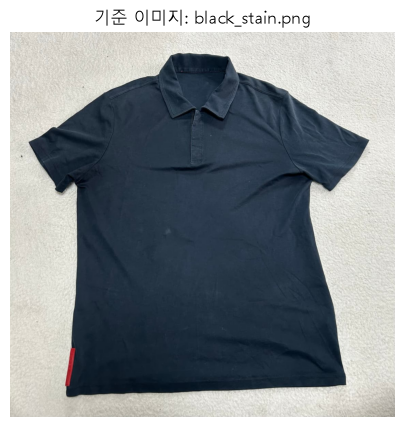

In [6]:
image_paths = qc_shared.list_images()
assert image_paths, "sample_images/ 에 이미지가 없습니다 (qc_shared.SHARED_IMAGE_DIR 참고)."
print(f"이미지 {len(image_paths)}장: {[p.name for p in image_paths]}")

# §1~§3은 이 기준 이미지 1장으로 단계별로 확인한다. §4에서 전체 배치를 돈다.
demo_path = image_paths[0]
demo_image = Image.open(demo_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(demo_image)
plt.title(f"기준 이미지: {demo_path.name}")
plt.axis("off")
plt.show()


## 1. Step 1 — SAM3 실시간 탐지

`sam3-border-overlay-check`의 검증된 파이프라인(옷 1회 세그먼트 -> 하자 탐지 -> 공통 후처리, bbox 유지로 결정된 그 방식)을 그대로 재사용한다 — 여기서 새로 탐지 로직을 만들지 않는다.


In [7]:
result = run_one(sam3_caller, demo_image)
kept = result["kept"]
print(f"하자 {len(kept)}건 탐지, garment_found={result['garment_found']}")
for inst in kept:
    label = qc_shared.KOREAN_LABELS.get(inst["type"], inst["type"])
    print(f"  [{inst['no']}] {label}  bbox={[round(v) for v in inst['bbox']]}")


하자 0건 탐지, garment_found=True


## 2. Step 2 — bbox 미표시 배치 VLM 설명 1회 호출

**원본 이미지 그대로**(bbox 안 그림) + 번호별 위치·유형을 알려주는 텍스트 프롬프트로 한 번만 호출한다. 넘버링 bbox를 이미지에 그려서 넣으면 VLM이 그 사각형 자체를 "작은 사각형 하자"로 묘사하는 문제가 실측으로 확인됐다 — 그래서 위치는 텍스트로만 준다(`loaders.build_defect_prompt`가 크롭 방식에서 위치를 안 묻는 것과 같은 원칙, `bbox_grid_position()` 재사용).


In [8]:
labels_by_inst = [{**inst, "label": qc_shared.KOREAN_LABELS.get(inst["type"], inst["type"])} for inst in kept]

# 번호 박스는 사람이 보는 미리보기용일 뿐, VLM 입력에는 원본 이미지가 그대로 들어간다.
preview = draw_numbered_boxes(demo_image, labels_by_inst)
plt.figure(figsize=(6, 6))
plt.imshow(preview)
plt.axis("off")
plt.title(f"{len(kept)}건 탐지 — 번호는 아래 배치 응답의 번호와 대응")
plt.show()

batch_started = time.perf_counter()
batch_raw_response = describe_defects_batch(
    vlm_bundle, demo_image, labels_by_inst, model_registry.DEMO_GARMENT_CATEGORY
)
batch_elapsed = time.perf_counter() - batch_started
print(f"배치 호출 {batch_elapsed:.1f}초\n원문:\n{batch_raw_response}")

expected_nos = [inst["no"] for inst in kept]
batch_parsed = parse_batch_response(batch_raw_response, expected_nos)
missing = missing_batch_numbers(batch_parsed)
if missing:
    print(f"\n[주의] 번호 {missing}는 배치 응답에서 못 찾았습니다.")
else:
    print("\n모든 번호가 파싱됐습니다.")


배치 호출 31.4초
원문:
1. 검은색 폴로 셔츠의 왼쪽 하의 끝부분에 붉은색 직선형 레이블이 약간 휘어져 있는 모습.  
2. 셔츠의 왼쪽 어깨 근처에 작은 흔적이나 접착물이 보이는 곳.  
3. 셔츠의 오른쪽 어깨 근처에 작은 흔적이나 접착물이 보이는 곳.  
4. 셔츠의 중앙 하단부에 약간의 얼룩이나 흔적이 보이는 곳.  
5. 셔츠의 오른쪽 하의 끝부분에 붉은색 직선형 레이블이 약간 휘어져 있는 모습.  
6. 셔츠의 중앙 하단부에 약간의 얼룩이나 흔적이 보이는 곳.  
7. 셔츠의 왼쪽 하의 끝부분에 붉은색 직선형 레이블이 약간 휘어져 있는 모습.  
8. 셔츠의 오른쪽 하의 끝부분에 붉은색 직선형 레이블이 약간 휘어져

모든 번호가 파싱됐습니다.


### 2-1. 진단용 모니터링 (2026-08-06 추가)

배치 응답이 이상할 때(번호 간 설명이 똑같다, 시간이 오래 걸린다) 무엇부터 봐야 하는지:
- **프롬프트 실제 내용**: 번호별 위치 힌트가 서로 다르게 들어갔는지
- **토큰 사용률**: 응답이 예산(`len(kept)*80`)을 거의 다 썼으면 EOS로 자연 종료가 아니라 잘렸을 가능성이 높다
- **번호 간 설명 중복**: 서로 다른 번호에 완전히 같은 문장이 나오면 그래도 위치 힌트를 무시하고 그 이미지에서 가장 눈에 띄는 걸 반복 묘사했다는 뜻(2026-08-06 실측: `small_pro.jpg`에서 6건 전부 로고 텍스트만 묘사, SAM3 위치는 서로 달랐는데도)
- **`hf_device_map`**: 4bit 로드인데 일부가 `cpu`/`disk`로 잡혀 있으면 그것부터 문제


In [ ]:
from collections import Counter

prompt_text = build_batch_prompt(
    labels_by_inst, demo_image.size, model_registry.DEMO_GARMENT_CATEGORY
)
tokenizer = vlm_bundle.processor.tokenizer
prompt_tokens = len(tokenizer(prompt_text).input_ids)
response_tokens = len(tokenizer(batch_raw_response).input_ids)
token_budget = max(1, len(kept)) * 80

print("--- 실제 프롬프트 ---")
print(prompt_text)
print(f"\n프롬프트 토큰 {prompt_tokens} / 응답 토큰 {response_tokens} (예산 {token_budget}, {response_tokens / token_budget:.0%} 사용)")
if response_tokens >= token_budget * 0.95:
    print("[의심] 응답이 예산을 거의 다 썼습니다 — EOS 자연 종료가 아니라 중간에 잘렸을 가능성이 높습니다.")

desc_counts = Counter(v for v in batch_parsed.values() if v)
dupes = {text: c for text, c in desc_counts.items() if c > 1}
if dupes:
    total_dup = sum(dupes.values())
    print(f"\n[의심] 서로 다른 번호에 동일한 설명이 반복됐습니다({total_dup}건) — 위치 힌트를 무시하고 이미지에서 가장 눈에 띄는 걸 반복 묘사했을 가능성이 높습니다:")
    for text, c in dupes.items():
        print(f"  {c}회 반복: {text[:60]}...")
else:
    print("\n번호별 설명이 전부 서로 다릅니다.")

device_map = getattr(vlm_bundle.model, "hf_device_map", None)
offloaded = {k: v for k, v in (device_map or {}).items() if v in ("cpu", "disk")}
if offloaded:
    print(f"\n[경고] 아래 모듈이 CPU/디스크에 있습니다(4bit면 이미 로드 시점에 에러가 났을 것이라 정상 로드됐다면 보통 비어 있음):\n{offloaded}")
else:
    print(
        "\n전체 모듈이 GPU에 있습니다." if device_map else
        "\nhf_device_map 정보 없음(모델 클래스에 따라 없을 수 있음)."
    )


## 3. Step 3 — 최종 JSON 조립

`bbox`/`defect_type`/`label`(SAM3) + `description`(VLM, 파싱 실패 시 `None`)만 담는다. **`상태`(사용자 응답)는 여기서 만들지 않는다** — AI는 판정만 하고, 그 finding에 대한 사용자 응답은 BE가 `key`로 관리한다.


In [9]:
def assemble_finding(inst, description, image_size):
    return {
        "no": inst["no"],
        "bbox": [round(v, 4) for v in inst["bbox"]],
        "defect_type": inst["type"],
        "label": qc_shared.KOREAN_LABELS.get(inst["type"], inst["type"]),
        # garment_section_label_ko()로 계산한 카테고리별 실제 부위명 — VLM에게 다시
        # 묻지 않고(hallucination 방지), description과 별개 필드로 항상 채운다.
        # 프롬프트에만 쓰고 최종 결과에는 안 담던 게 버그였다(2026-08-06). 부위명을
        # "오른쪽 중앙" 같은 순수 기하학적 표현에서 "오른쪽 어깨" 식 옷 부위명으로
        # 바꾼 것도 2026-08-06(카테고리는 데모 고정값, 실제 분류 없음).
        "section": garment_section_label_ko(
            inst["bbox"], image_size, model_registry.DEMO_GARMENT_CATEGORY
        ),
        "confidence": round(inst["confidence"], 4),
        "description": description,
    }


final_findings = [
    assemble_finding(inst, batch_parsed.get(inst["no"]), demo_image.size) for inst in kept
]
print(jsonlib.dumps(final_findings, ensure_ascii=False, indent=2))


[]


## 4. 이미지 전체 배치 실행 + 결과 저장

§1~§3을 이미지마다 반복해서 최종 JSON을 모은다. 개별 이미지를 다시 자세히 보고 싶으면 `demo_path`/`demo_image`를 바꿔서 §1부터 재실행한다.


In [10]:
from pathlib import Path

OUTPUT_DIR = Path("./outputs/batch_pipeline_check")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary = []
for path in image_paths:
    image = Image.open(path).convert("RGB")
    row_result = run_one(sam3_caller, image)
    row_kept = row_result["kept"]
    if not row_kept:
        summary.append({"image": path.name, "findings": []})
        continue

    row_insts = [{**inst, "label": qc_shared.KOREAN_LABELS.get(inst["type"], inst["type"])} for inst in row_kept]
    row_response = describe_defects_batch(
        vlm_bundle, image, row_insts, model_registry.DEMO_GARMENT_CATEGORY
    )
    row_expected = [inst["no"] for inst in row_kept]
    row_parsed = parse_batch_response(row_response, row_expected)

    row_findings = [
        assemble_finding(inst, row_parsed.get(inst["no"]), image.size) for inst in row_kept
    ]
    # raw_response를 결과 JSON에도 남긴다 — 파싱 실패 원인을 나중에 원문으로 직접 확인할 수 있게.
    summary.append({"image": path.name, "raw_response": row_response, "findings": row_findings})
    missing_count = len(missing_batch_numbers(row_parsed))
    print(f"{path.name}: 하자 {len(row_kept)}건, 누락 {missing_count}건")
    if missing_count:
        print(f"  [원문 미리보기] {row_response[:300]!r}")

out_json = OUTPUT_DIR / "result.json"
out_json.write_text(jsonlib.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\n결과 저장 -> {out_json}")


denim.jpg: 하자 1건, 누락 1건
fix.jpg: 하자 7건, 누락 7건
levis_patch.jpg: 하자 5건, 누락 5건
scratch.jpg: 하자 6건, 누락 6건
small_pro.jpg: 하자 6건, 누락 6건
vintage_t.png: 하자 39건, 누락 39건

결과 저장 -> outputs\batch_pipeline_check\result.json


## 결론 (2026-08-06 실행 결과 기준)

- **번호가 누락되거나 헷갈린 사례가 있었는가**: 있었다. 원인은 두 가지로 분리된다.
  1. **파싱 버그(수정됨)**: `build_batch_prompt()`가 입력 목록에서 "1번 (위치 부근): '유형' 하자"처럼 "번"을 붙여 예시를 보여주는데, 모델이 출력에서도 "1번. 설명" 식으로 그 스타일을 그대로 따라 했다. 기존 `_BATCH_LINE_PATTERN`은 숫자 바로 뒤에 구분자(`.`/`:`/`)`)가 와야 매칭돼서 이 경우를 전부 놓쳤다 — 실제로 findings가 있던 이미지 전부(denim/fix/scratch/small_pro 등)가 100% 누락이었다. `loaders.py`의 정규식에 선택적 `번?`을 추가해 해소했고, 캡처된 `outputs/batch_pipeline_check/result.json`의 `raw_response`를 재파싱해서 확인했다(denim/fix/scratch/small_pro는 누락 0건으로 해소).
  2. **생성 자체의 한계(미해결)**: finding 수가 많은 이미지(`levis_patch.jpg` 8건, `vintage_t.png` 34건)는 파싱 문제가 아니라 모델 응답 자체가 무너졌다 — 8건짜리는 5번째 답변 중간에 문장이 끊겼고 1~5번 설명이 전부 같은 문구로 반복됐다. 34건짜리는 8번째까지만 답하고 멈췄고, "위치는 다시 언급하지 말라"는 지시를 어기고 위치 표현("오른쪽 중앙 부근" 등)을 계속 반복했다. `max_new_tokens`를 건수만큼 늘려도(건수×80) 해결되지 않는, 대상이 많아질수록 instruction-following이 무너지는 근본적인 한계로 보인다.
- **bbox를 안 보여줬는데도 설명이 그 위치에 맞게 나오는가**: finding이 적은 이미지(1~6건)에서는 "사각형" 같은 아티팩트 언급 없이 시각적 특징 위주로 잘 나왔다. finding이 많아지면(8건 이상) 위 반복/위치 재언급 문제가 겹쳐 신뢰하기 어렵다.
- **채택할 만한가**: finding 수가 적을 때(대략 1~6건)는 조건부로 쓸 만하지만, 지금 그대로 프로덕션에 넣기는 어렵다. 실제 서비스에서도 하자 오탐이 몰리는 이미지가 나올 수 있는 이상, 크롭 방식(`describe_defect`, 건별 개별 호출) 대비 안정성이 떨어진다. 이미지 인코딩 1회로 얻는 지연시간 이득보다 이 리스크가 커 보여, **현재 프로덕션(quality_vlm, 크롭 방식) 유지를 권장**한다.

### 후속 작업
- 채택한다면 `docs/plans/AI/`에 `describer.py`/`prompts.py` 반영 설계 계획을 먼저 쓴다(CH006/CH011 선례). 여기 코드를 그대로 승격하지 않는다 — 프로덕션은 계획 문서 승인 후에만 손댄다.
- finding 수가 많을 때의 반복/조기중단 문제를 풀어보고 싶다면: (a) finding 개수 임계값을 넘으면 배치를 여러 청크로 나눠 호출, (b) 크롭 방식으로 폴백하는 하이브리드 전략을 후속 스파이크로 검증해볼 수 있다. 지금 단계에서는 스코프 밖으로 남겨둔다.
